<a href="https://colab.research.google.com/github/baharbazargan62/6-kyu-FizzBuzz-Backwards/blob/main/Copy_of_Untitled6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ucimlrepo
from ucimlrepo import fetch_ucirepo

In [ ]:
!pip install -q dtreeviz
import dtreeviz

In [ ]:
import pandas as pd
import seaborn as sns

In [ ]:
rides = pd.read_csv(
    'https://raw.githubusercontent.com/gerberl/6G7V0015-2324/main/datasets/bike.csv'
)
rides.head(10)

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt,days_since_2011
0,WINTER,2011,JAN,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,8.175849,80.5833,10.749882,985,0
1,WINTER,2011,JAN,NO HOLIDAY,SUN,NO WORKING DAY,MISTY,9.083466,69.6087,16.652113,801,1
2,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,1.229108,43.7273,16.636703,1349,2
3,WINTER,2011,JAN,NO HOLIDAY,TUE,WORKING DAY,GOOD,1.400000,59.0435,10.739832,1562,3
4,WINTER,2011,JAN,NO HOLIDAY,WED,WORKING DAY,GOOD,2.666979,43.6957,12.522300,1600,4
5,WINTER,2011,JAN,NO HOLIDAY,THU,WORKING DAY,GOOD,1.604356,51.8261,6.000868,1606,5
6,WINTER,2011,JAN,NO HOLIDAY,FRI,WORKING DAY,MISTY,1.236534,49.8696,11.304642,1510,6
7,WINTER,2011,JAN,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,-0.245000,53.5833,17.875868,959,7
8,WINTER,2011,JAN,NO HOLIDAY,SUN,NO WORKING DAY,GOOD,-1.498349,43.4167,24.250650,822,8
9,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,-0.910849,48.2917,14.958889,1321,9


In [ ]:
sns.set(
    { "figure.figsize": (6, 4) },
    style='ticks',
    color_codes=True,
    font_scale=0.8
)

In [ ]:
rides.isnull().sum()


,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0
hum,0
windspeed,0


In [ ]:
rides_numeric=rides.select_dtypes(include="number")
rides_numeric.head()

,yr,temp,hum,windspeed,cnt,days_since_2011
0,2011,8.175849,80.5833,10.749882,985,0
1,2011,9.083466,69.6087,16.652113,801,1
2,2011,1.229108,43.7273,16.636703,1349,2
3,2011,1.400000,59.0435,10.739832,1562,3
4,2011,2.666979,43.6957,12.522300,1600,4


In [ ]:
X = rides_numeric.drop(columns="cnt")
y = rides_numeric["cnt"]

In [ ]:
X.head()
y.head()

,cnt
0,985
1,801
2,1349
3,1562
4,1600


<Axes: xlabel='cnt', ylabel='Count'>

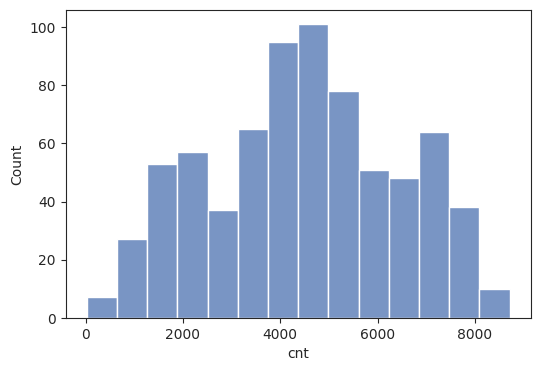

In [ ]:
sns.histplot(y)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
from sklearn.metrics import PredictionErrorDisplay
from sklearn.tree import export_text

In [ ]:
X_train , X_test , y_train , y_test = train_test_split(X , y, test_size=0.2 , random_state=42 )

In [ ]:
dt_model=DecisionTreeRegressor(max_depth=4)
knn_model=KNeighborsRegressor(11)

In [ ]:
dt_model.fit(X_train , y_train)

DecisionTreeRegressor(max_depth=4)

In [ ]:
knn_model.fit(X_train , y_train)

KNeighborsRegressor(n_neighbors=11)

In [ ]:
dt_pred =dt_model.predict(X_test)
knn_pred=knn_model.predict(X_test)

In [ ]:
knn_pred[:15]

array([4978.8, 1512.3, 4153.9, 6616.6, 7769.7, 6279.8, 1658.3, 2833.7,
       6296.5, 6316.6, 4176.4, 2918.6, 4894.2, 4713.2, 1961.3])

In [ ]:
dt_pred[:15]

array([6980.76865672, 1398.86538462, 3551.24418605, 6980.76865672,
       6980.76865672, 6980.76865672, 1398.86538462, 3551.24418605,
       6980.76865672, 5903.46666667, 2088.33333333, 3551.24418605,
       4572.55555556, 4934.13043478, 1398.86538462])

In [ ]:
X_test.head(5)

,yr,temp,hum,windspeed,days_since_2011
703,2012,14.364151,73.3750,11.666643,703
33,2011,0.786979,43.7826,18.609384,33
300,2011,7.549151,58.5833,15.375093,300
456,2012,12.014151,67.6250,11.541889,456
633,2012,17.850000,57.0000,15.833507,633


In [ ]:
y_test.head()

,cnt
703,6606
33,1550
300,3747
456,6041
633,7538
